---
title: "3.4.d Escenarios de calor (CMIP6)"
short_title: "d. Escenarios"
subtitle: "Trayectorias de temperatura, días calurosos y noches tropicales hasta 2100"
description: "Proyecciones del ensamble CMIP6 del Banco Mundial para el calor en Leticia y días sobre el umbral actual con el método delta."
keywords: [calor, CMIP6, CCKP, SSP, noches tropicales, índice de calor, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/34_calor/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El calor es la amenaza con la señal de cambio climático **más robusta**: todos los modelos y escenarios proyectan
calentamiento. La pregunta es cuánto y qué tan rápido. Esta página usa el ensamble de 25 modelos CMIP6 con
reducción de escala estadística (NEX-GDDP-CMIP6) que publica el Portal de Conocimiento sobre Cambio Climático del
Banco Mundial [@cckp2024; @thrasher2022].

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import clima, fuentes, viz
from leticia.config import aoi_cfg, parametros

## 1. Trayectoria de la temperatura máxima

Diferencia ERA5 − CCKP en 1995–2014: +0.28 °C (se resta a ERA5 para comparar en la misma base).

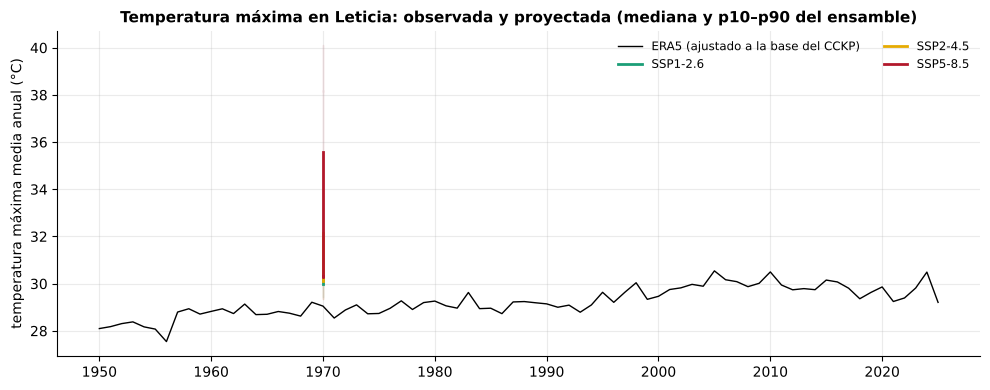

In [3]:
tr = fuentes.cckp_trayectoria("tasmax")
base_cckp = float(fuentes.cckp_historico(["tasmax"]).iloc[0])
era = fuentes.clima_diario()
tmax_anual = era["temperature_2m_max"].groupby(era.index.year).mean()
tmax_anual = tmax_anual[tmax_anual.index < pd.Timestamp.today().year]
sesgo = tmax_anual.loc[1995:2014].mean() - base_cckp
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tmax_anual.index, tmax_anual - sesgo, color="k", lw=1, label="ERA5 (ajustado a la base del CCKP)")
for esc in ("ssp126", "ssp245", "ssp585"):
    ax.fill_between(tr.index, tr[f"{esc}_p10"], tr[f"{esc}_p90"], color=viz.ESCENARIOS[esc], alpha=0.12)
    ax.plot(tr.index, tr[f"{esc}_median"], color=viz.ESCENARIOS[esc], lw=2, label=viz.NOMBRE_ESC[esc])
ax.set_ylabel("temperatura máxima media anual (°C)")
ax.set_title("Temperatura máxima en Leticia: observada y proyectada (mediana y p10–p90 del ensamble)")
ax.legend(ncol=2)
fig.tight_layout()
display(Markdown(f"Diferencia ERA5 − CCKP en 1995–2014: {sesgo:+.2f} °C (se resta a ERA5 para comparar en la misma base)."))

In [4]:
viz.pie(viz.nota_fuente("proyecciones_cckp", "clima_diario"))

Fuente: Banco Mundial – Climate Change Knowledge Portal (CCKP) — CMIP6 0,25° (reducción de escala estadística), SSP1-2.6, SSP2-4.5, SSP5-8.5; ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°.

## 2. Indicadores de calor extremo

In [5]:
VARS = {"tas": "temperatura media (°C)", "tasmax": "temperatura máxima (°C)", "txx": "máxima absoluta anual (°C)",
        "hd35": "días con Tmax > 35 °C", "hi35": "días con índice de calor > 35 °C", "tr26": "noches con Tmin > 26 °C"}
tabla = fuentes.cckp_tabla(list(VARS))
base = fuentes.cckp_historico(list(VARS))
med = tabla[tabla.percentil == "median"].pivot_table(index="variable", columns=["periodo", "escenario"], values="valor")
med.columns = [f"{p} {viz.NOMBRE_ESC[e]}" for p, e in med.columns]
med.insert(0, "1995–2014 (base)", base)
med.index = [VARS[v] for v in med.index]
display(Markdown("**Valor de base y cambio proyectado (mediana del ensamble):**"))
display(med.round(1))

Valor de base y cambio proyectado (mediana del ensamble):

,1995–2014 (base),2040-2059 SSP1-2.6,2040-2059 SSP2-4.5,2040-2059 SSP5-8.5,2080-2099 SSP1-2.6,2080-2099 SSP2-4.5,2080-2099 SSP5-8.5
días con Tmax > 35 °C,0.20,3.20,4.90,19.60,4.20,26.00,152.70
días con índice de calor > 35 °C,7.10,64.10,85.10,134.10,69.90,186.90,320.80
temperatura media (°C),26.70,1.00,1.20,1.80,1.10,2.10,4.60
temperatura máxima (°C),29.90,1.00,1.20,1.80,1.10,2.20,4.80
noches con Tmin > 26 °C,0.80,28.50,53.00,114.60,40.20,164.20,334.60
máxima absoluta anual (°C),35.80,1.60,2.00,3.50,1.30,3.40,8.50


**Lectura.** La temperatura máxima media sube entre ~1 °C (SSP1-2.6) y ~2 °C (SSP5-8.5) hacia mediados de siglo,
y hasta 4–5 °C a final de siglo con altas emisiones. Lo más relevante para la salud es el aumento de los **días
con índice de calor sobre 35 °C** y de las **noches tropicales**, que eliminan el alivio nocturno: pasan de ser
raros a ocurrir durante buena parte del año. Coincide con la Tercera Comunicación Nacional, que proyecta para
Amazonas aumentos de 1,5 °C (2041–2070) y 2,4 °C (2071–2100) de la temperatura media [@ideam2017tcncc].

## 3. Días sobre el umbral actual (método delta)

In [6]:
pc = parametros()["calor"]
base_p = tuple(aoi_cfg()["clima"]["periodo_base"])
tmax = era["temperature_2m_max"]
ref = tmax[(tmax.index.year >= base_p[0]) & (tmax.index.year <= base_p[1])]
umbral = clima.umbral_percentil(tmax, pc["percentil_umbral"], base_p)
tabla_tx = tabla[(tabla.variable == "tasmax")]
filas = []
for (per, esc), g in tabla_tx.groupby(["periodo", "escenario"]):
    d = g.set_index("percentil")["valor"]
    fila = {"periodo": per, "escenario": viz.NOMBRE_ESC[esc]}
    for q in ("p10", "median", "p90"):
        futura = ref + d[q]
        fila[f"días/año ({q})"] = (futura > umbral).groupby(futura.index.year).sum().mean()
    filas.append(fila)
res = pd.DataFrame(filas).set_index(["periodo", "escenario"])
display(Markdown(f"Umbral actual: Tmax > **{umbral:.1f} °C** (p{pc['percentil_umbral']} de {base_p[0]}–{base_p[1]}); hoy ≈ 36 días/año por construcción."))
display(res.round(0))

Umbral actual: Tmax > 32.2 °C (p90 de 1991–2020); hoy ≈ 36 días/año por construcción.

días/año (p10)  días/año (median)  días/año (p90)
periodo   escenario                                                   
2040-2059 SSP1-2.6            66.00             100.00          173.00
          SSP2-4.5            78.00             115.00          205.00
          SSP5-8.5            78.00             155.00          265.00
2080-2099 SSP1-2.6            54.00             100.00          205.00
          SSP2-4.5            85.00             189.00          299.00
          SSP5-8.5           181.00             338.00          365.00

El método delta suma a la serie diaria observada de 1991–2020 el cambio medio proyectado de la temperatura
máxima. Es sencillo y transparente, pero no cambia la variabilidad diaria: los resultados indican el orden de
magnitud del desplazamiento, no la forma exacta de las olas futuras. Aun en el escenario más bajo, lo que hoy es un
día caluroso excepcional se volverá común.